# TAREA 1: EVALUACIÓN DE LA PROBAILIDAD DE GANAR
Vamos a evaluar la probabilidad de ganar un partido a 5 sets en tenis en base a la probabilidad de ganar un punto normal y un punto clave. Además, este problema será aplicado a otros deportes de raqueta como el badminton y el ping pong.
El caso de Roger Federer: En una entrevista, Federer indica que su porcentage de puntos ganados en toda su carrera es del 54%, lo cúal, parece una cifra relativamente baja para un tenista de este calibre. Por otro lado, su porcentaje de partidos ganados es de un 80%. ¿Cómo es esto posible? 

![Descripción](https://www.infobae.com/resizer/v2/https%3A%2F%2Fs3.amazonaws.com%2Farc-wordpress-client-uploads%2Finfobae-wp%2Fwp-content%2Fuploads%2F2016%2F07%2F04065126%2FRoger-Federer-Wimbledon-2016-1920.jpg?auth=a2f986792c15f272f1085668498250368752403e2a7b36c173cd9b4becdbbe33&smart=true&width=992&quality=85)

## 1. Evaluar porcentaje de victorias según porcentaje de puntos ganados
El porcentaje de ganar un punto normal se ha establecido en 0.5, mientras que el de ganar un punto clave es varibale. 

In [36]:
# Simula partidos de tenis y cuenta cuántos puntos gana A.
import random
import numpy as np
import matplotlib.pyplot as plt

# Contadores usados para calcular el porcentaje real de puntos ganados por A.
PUNTOS_JUGADOS = 0
PUNTOS_GANADOS = 0

# En un punto normal, A gana según la probabilidad indicada.
def simular_punto(p_ganar_punto_A):
    return 'A' if random.random() < p_ganar_punto_A else 'B'

# En un punto clave se usa una probabilidad distinta, definida por separado.
def simular_punto_clave(p_ganar_punto_clave_A):
    return 'A' if random.random() < p_ganar_punto_clave_A else 'B'

# Juega un juego hasta que alguien gane por dos puntos de diferencia.
def simular_juego_normal(p_ganar_punto_A, p_ganar_clave_A):
    global PUNTOS_JUGADOS, PUNTOS_GANADOS
    puntos_A = 0
    puntos_B = 0
    while True:
        # Al llegar a 40 o a ventaja, los puntos se consideran clave.
        if (puntos_A >= 3 and puntos_A - puntos_B > 0) or (puntos_B >= 3 and puntos_B - puntos_A > 0) :
            if simular_punto_clave(p_ganar_clave_A) == 'A':
                puntos_A += 1
                PUNTOS_GANADOS += 1
            else:
                puntos_B += 1

        elif simular_punto(p_ganar_punto_A) == 'A':
            puntos_A += 1            
            PUNTOS_GANADOS += 1
        else:
            puntos_B += 1
        # Se registra cada punto jugado para calcular el porcentaje al final.
        PUNTOS_JUGADOS += 1        
            
        if puntos_A >= 4 and puntos_A - puntos_B >= 2:
            return 'A'
        elif puntos_B >= 4 and puntos_B - puntos_A >= 2:
            return 'B'

# Juega el desempate: se necesitan 7 puntos (o los indicados) y ganar por dos.
def simular_tiebreak(p_ganar_punto_A, p_ganar_clave_A, puntos_objetivo=7):
    global PUNTOS_JUGADOS, PUNTOS_GANADOS
    puntos_A = 0
    puntos_B = 0
    while True:
        # Los puntos a partir del objetivo también se tratan como puntos clave.
        if (puntos_A >= puntos_objetivo and puntos_A - puntos_B > 0) or (puntos_B >= puntos_objetivo and puntos_B - puntos_A > 0) :
            if simular_punto_clave(p_ganar_clave_A) == 'A':
                puntos_A += 1
                PUNTOS_GANADOS += 1
            else:
                puntos_B += 1

        elif simular_punto(p_ganar_punto_A) == 'A':
            puntos_A += 1
            PUNTOS_GANADOS += 1
        else:
            puntos_B += 1
        PUNTOS_JUGADOS += 1
            
        if puntos_A >= puntos_objetivo and puntos_A - puntos_B >= 2:
            return 'A'
        elif puntos_B >= puntos_objetivo and puntos_B - puntos_A >= 2:
            return 'B'

# Simula un set; al llegar a 6-6 se decide con un tie-break.
def simular_set(p_ganar_punto_A, p_ganar_clave_A, es_quinto_set=False):
    juegos_A = 0
    juegos_B = 0
    while True:
        if juegos_A == 6 and juegos_B == 6:
            # En el quinto set el desempate se juega a 10; en los demás, a 7.
            puntos_tb = 10 if es_quinto_set else 7
            return simular_tiebreak(p_ganar_punto_A, p_ganar_clave_A, puntos_objetivo=puntos_tb)
        
        ganador_juego = simular_juego_normal(p_ganar_punto_A, p_ganar_clave_A)
        if ganador_juego == 'A':
            juegos_A += 1
        else:
            juegos_B += 1
            
        if juegos_A >= 6 and juegos_A - juegos_B >= 2:
            return 'A'
        elif juegos_B >= 6 and juegos_B - juegos_A >= 2:
            return 'B'

# Simula un partido al mejor de cinco sets: gana quien consigue tres sets.
def simular_partido(prob_A, prob_clave_A):
    sets_A = 0
    sets_B = 0
    num_set = 1
    while sets_A < 3 and sets_B < 3:
        es_quinto = (num_set == 5)
        ganador_set = simular_set(prob_A, prob_clave_A, es_quinto_set=es_quinto)
        if ganador_set == 'A':
            sets_A += 1
        else:
            sets_B += 1
        num_set += 1
    return 'A' if sets_A == 3 else 'B'

# -------------------------------------------------------------
# SIMULACIÓN
# -------------------------------------------------------------
if __name__ == "__main__":
    # Se fija en 50% la probabilidad normal y se prueban distintas probabilidades clave.
    probs_punto = 0.5
    probs_punto_clave = np.linspace(0.25, 0.75, 26)
    
    # Para cada probabilidad clave se simulan muchos partidos y se estima el porcentaje de victorias.
    simulaciones_por_prob = 1500

    porcentajes_victoria = []
    pct_putnos_victoria_array = []

    print("Ejecutando simulación...")
    for p in probs_punto_clave:
        victorias = sum(1 for _ in range(simulaciones_por_prob) if simular_partido(probs_punto, p) == 'A')
        # Convierte el número de victorias en un porcentaje.
        pct = (victorias / simulaciones_por_prob) * 100
        porcentajes_victoria.append(pct)
        # pyrefly: ignore [division-by-zero]
        # Guarda el porcentaje de puntos ganados en los partidos de esta tanda.
        pct_putnos_victoria_array.append(PUNTOS_GANADOS/PUNTOS_JUGADOS * 100)        
        # pyrefly: ignore [division-by-zero]
        print(f"Prob. punto: {PUNTOS_GANADOS/PUNTOS_JUGADOS*100:.1f}% -> % Victorias partido: {pct:.1f}%")
        # Reinicia los contadores para medir la siguiente probabilidad clave por separado.
        PUNTOS_JUGADOS = 0
        PUNTOS_GANADOS = 0

    # Pasa las probabilidades clave a porcentaje para usarlas en el gráfico.
    prob_clave_pct = probs_punto_clave * 100

Ejecutando simulación...
Prob. punto: 42.4% -> % Victorias partido: 0.0%
Prob. punto: 43.0% -> % Victorias partido: 0.3%
Prob. punto: 43.8% -> % Victorias partido: 1.5%
Prob. punto: 44.5% -> % Victorias partido: 2.1%
Prob. punto: 45.0% -> % Victorias partido: 3.4%
Prob. punto: 45.6% -> % Victorias partido: 5.7%
Prob. punto: 46.1% -> % Victorias partido: 8.5%
Prob. punto: 46.8% -> % Victorias partido: 12.1%
Prob. punto: 47.3% -> % Victorias partido: 17.3%
Prob. punto: 47.8% -> % Victorias partido: 23.0%
Prob. punto: 48.6% -> % Victorias partido: 31.9%
Prob. punto: 49.0% -> % Victorias partido: 38.1%
Prob. punto: 49.8% -> % Victorias partido: 47.3%
Prob. punto: 50.4% -> % Victorias partido: 55.3%
Prob. punto: 51.0% -> % Victorias partido: 62.3%
Prob. punto: 51.5% -> % Victorias partido: 68.9%
Prob. punto: 52.1% -> % Victorias partido: 75.2%
Prob. punto: 52.7% -> % Victorias partido: 84.1%
Prob. punto: 53.3% -> % Victorias partido: 86.9%
Prob. punto: 53.8% -> % Victorias partido: 91.3%
Pr

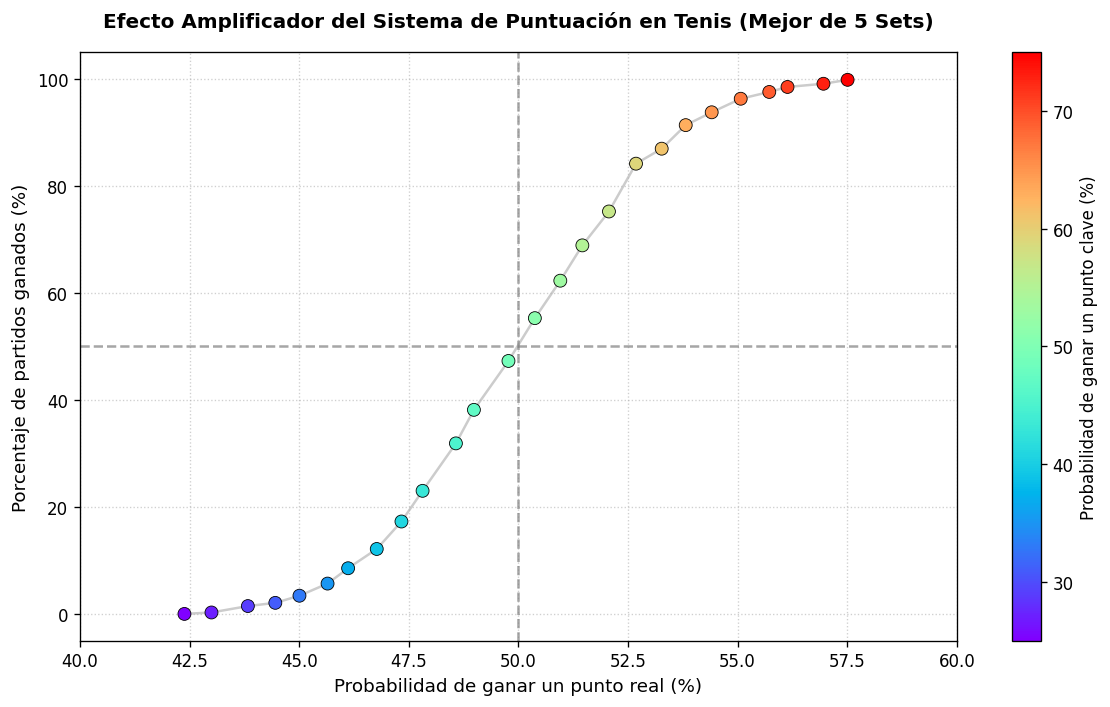

In [37]:
plt.figure(figsize=(10, 6), dpi=120)

    # Línea guía continua de fondo
plt.plot(pct_putnos_victoria_array, porcentajes_victoria, color='gray', linestyle='-', alpha=0.4, linewidth=1.5, zorder=1)

    # Puntos coloreados según la probabilidad de ganar un punto clave
scatter = plt.scatter(
        pct_putnos_victoria_array, 
        porcentajes_victoria, 
        c=prob_clave_pct,      # <--- Mapeo al % de punto clave
        cmap='rainbow', 
        s=60, 
        edgecolors='black', 
        linewidth=0.5,
        zorder=2
    )

    # Barra lateral indicando la probabilidad de punto clave
cbar = plt.colorbar(scatter)
cbar.set_label('Probabilidad de ganar un punto clave (%)', fontsize=10)

    # Líneas de referencia (50% punto / 50% partido)
plt.axvline(x=50, color='gray', linestyle='--', alpha=0.7)
plt.axhline(y=50, color='gray', linestyle='--', alpha=0.7)

plt.title('Efecto Amplificador del Sistema de Puntuación en Tenis (Mejor de 5 Sets)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Probabilidad de ganar un punto real (%)', fontsize=11)
plt.ylabel('Porcentaje de partidos ganados (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(40, 60)
plt.ylim(-5, 105)
plt.tight_layout()
plt.savefig('simulacion_tenis_punto_clave_color.png')
plt.show()

## 2. Evaluar el porcentaje de victorias según porcentage de puntos normales y críticos ganados
El porcentage de puntos normales y puntos clave ganados es variable.

In [38]:
import random
import seaborn as sns

# -------------------------------------------------------------
# EJECUCIÓN Y GENERACIÓN DE MATRIZ DE SIMULACIÓN
# -------------------------------------------------------------
if __name__ == "__main__":
    # Rango de probabilidades de 40% a 60%
    probs_normal = np.linspace(0.40, 0.60, 11)
    probs_clave = np.linspace(0.40, 0.60, 11)
    simulaciones_por_celda = 500

    matriz_victorias = np.zeros((len(probs_clave), len(probs_normal)))

    print("Ejecutando matriz de simulación...")
    for i, p_c in enumerate(probs_clave):
        for j, p_n in enumerate(probs_normal):
            victorias = sum(1 for _ in range(simulaciones_por_celda) if simular_partido(p_n, p_c) == 'A')
            matriz_victorias[i, j] = (victorias / simulaciones_por_celda) * 100

Ejecutando matriz de simulación...


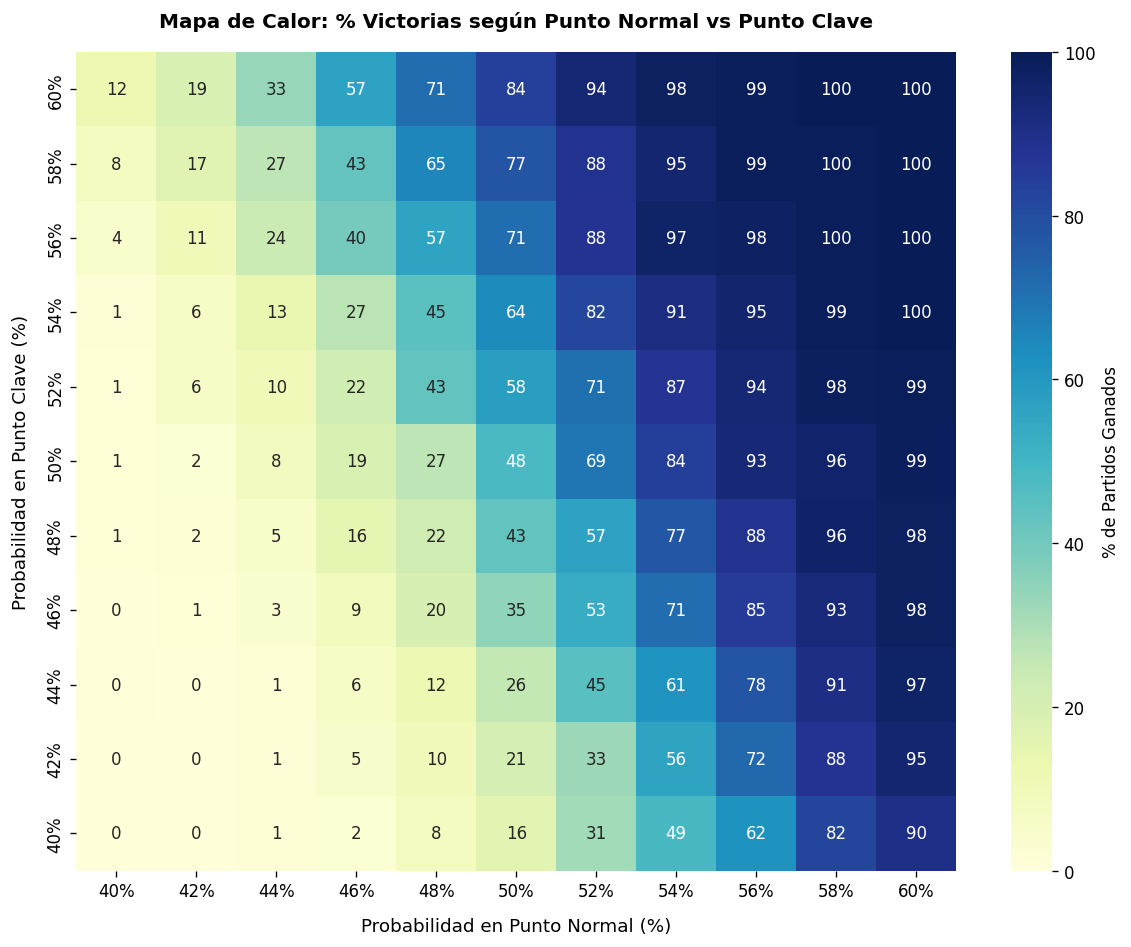

In [39]:
# 1. GENERACIÓN DEL MAPA DE CALOR
plt.figure(figsize=(10, 8), dpi=120)
sns.heatmap(
        matriz_victorias, 
        annot=True, 
        fmt=".0f", 
        cmap="YlGnBu", 
        xticklabels=[f"{p*100:.0f}%" for p in probs_normal],
        yticklabels=[f"{p*100:.0f}%" for p in probs_clave],
        cbar_kws={'label': '% de Partidos Ganados'}
    )

plt.title('Mapa de Calor: % Victorias según Punto Normal vs Punto Clave', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Probabilidad en Punto Normal (%)', fontsize=11, labelpad=10)
plt.ylabel('Probabilidad en Punto Clave (%)', fontsize=11, labelpad=10)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig('matriz_victorias_tenis_puntos_claves.png')
plt.show()

## 3. Evaluar el porcentage de victorias según probabilidad de ganar un punto (tenis, bádminton y ping pong)

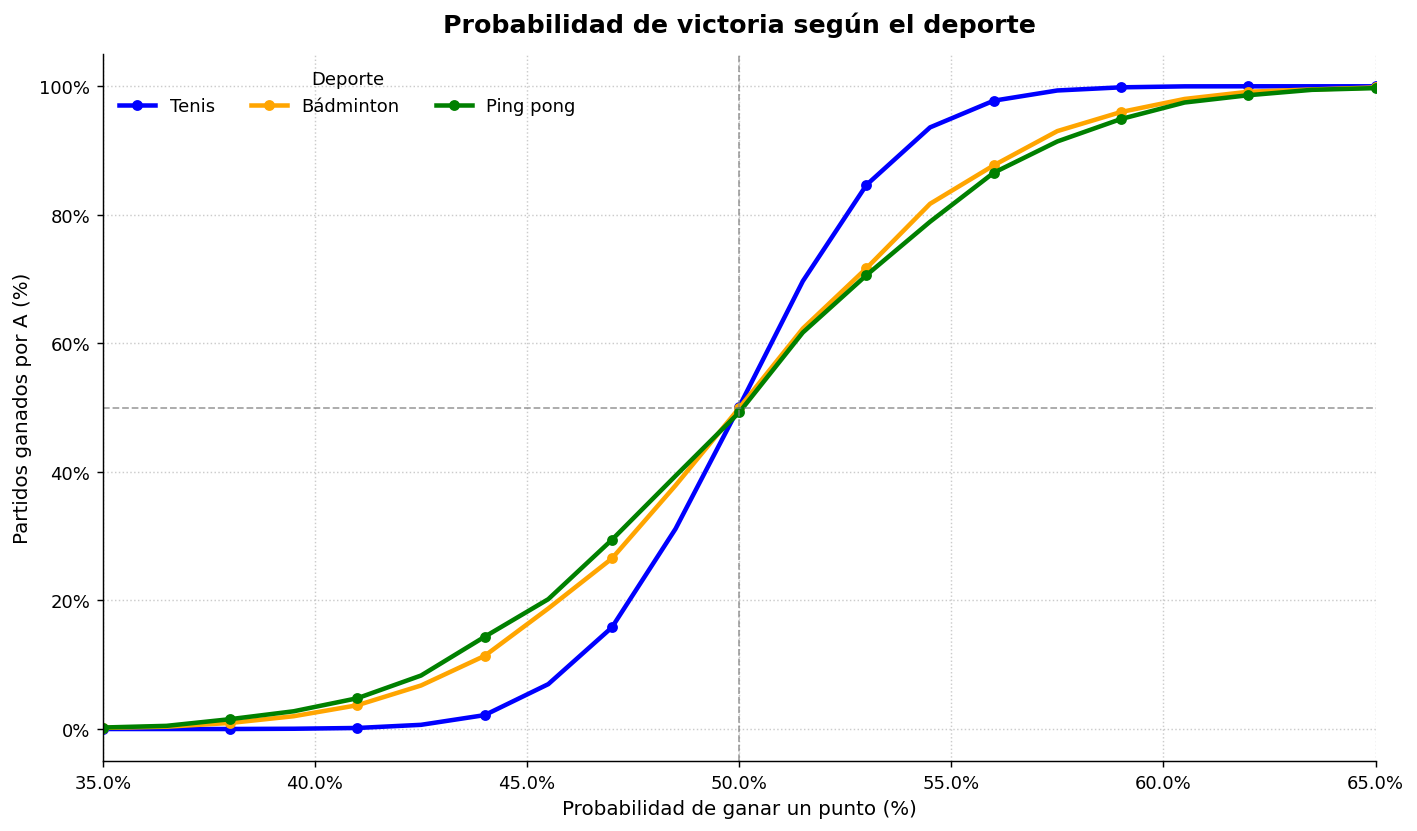

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Una semilla fija permite repetir la simulación y obtener los mismos resultados.
rng = np.random.default_rng(42)
NUM_PARTIDOS = 10_000
# Se prueban probabilidades del 35% al 65%, en pasos de 1.5 puntos porcentuales.
PROBABILIDADES = np.linspace(0.35, 0.65, 21)


def repartir_puntos(puntos_a, puntos_b, activos, probabilidad):
    """Juega un punto para cada partido que todavía sigue activo."""
    # Todos los puntos usan la misma probabilidad, sin importar el marcador.
    gana_a = (rng.random(puntos_a.size) < probabilidad) & activos
    puntos_a += gana_a
    puntos_b += activos & ~gana_a


def simular_juego_tenis(activos, probabilidad):
    """Simula juegos de tenis; se gana con al menos cuatro puntos y dos de ventaja."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= 4) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= 4) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_tiebreak(activos, objetivo, probabilidad):
    """Simula un tie-break: llegar al objetivo y ganar por dos puntos."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= objetivo) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= objetivo) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_set_tenis(activos, es_quinto_set, probabilidad):
    """Simula un set de tenis y el tie-break cuando el marcador llega a 6-6."""
    juegos_a = np.zeros(activos.size, dtype=int)
    juegos_b = np.zeros(activos.size, dtype=int)

    while True:
        # Un set se gana con seis juegos y dos de ventaja; 7-6 indica tie-break ganado.
        gana_a = ((juegos_a >= 6) & (juegos_a - juegos_b >= 2)) | ((juegos_a == 7) & (juegos_b == 6))
        gana_b = ((juegos_b >= 6) & (juegos_b - juegos_a >= 2)) | ((juegos_b == 7) & (juegos_a == 6))
        pendientes = activos & ~(gana_a | gana_b)
        if not np.any(pendientes):
            return gana_a

        # Los partidos 6-6 juegan tie-break; los demás continúan con un juego normal.
        en_tiebreak = pendientes & (juegos_a == 6) & (juegos_b == 6)
        en_juego = pendientes & ~en_tiebreak
        ganador_juego = simular_juego_tenis(en_juego, probabilidad)
        juegos_a += en_juego & ganador_juego
        juegos_b += en_juego & ~ganador_juego

        if np.any(en_tiebreak):
            # En esta simulación, el tie-break del quinto set se juega a 10 y los otros a 7.
            objetivo = np.where(es_quinto_set, 10, 7)
            ganador_tiebreak = simular_tiebreak(en_tiebreak, objetivo, probabilidad)
            juegos_a += en_tiebreak & ganador_tiebreak
            juegos_b += en_tiebreak & ~ganador_tiebreak


def simular_partidos_tenis(probabilidad, cantidad):
    """Simula partidos de tenis al mejor de cinco sets."""
    sets_a = np.zeros(cantidad, dtype=int)
    sets_b = np.zeros(cantidad, dtype=int)

    while True:
        # Gana el partido quien obtiene tres sets; los partidos ya decididos se dejan inactivos.
        activos = (sets_a < 3) & (sets_b < 3)
        if not np.any(activos):
            return sets_a >= 3

        es_quinto_set = (sets_a + sets_b) == 4
        ganador_set = simular_set_tenis(activos, es_quinto_set, probabilidad)
        sets_a += activos & ganador_set
        sets_b += activos & ~ganador_set


def simular_set_por_puntos(activos, objetivo, probabilidad):
    """Simula un set de bádminton o ping pong, ganado por puntos y con dos de ventaja."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= objetivo) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= objetivo) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_partidos_por_sets(probabilidad, cantidad, puntos_set, sets_necesarios):
    """Simula partidos donde cada set se gana alcanzando una cantidad de puntos."""
    sets_a = np.zeros(cantidad, dtype=int)
    sets_b = np.zeros(cantidad, dtype=int)

    while True:
        # Solo siguen activos los partidos en los que nadie ha ganado todavía.
        activos = (sets_a < sets_necesarios) & (sets_b < sets_necesarios)
        if not np.any(activos):
            return sets_a >= sets_necesarios

        ganador_set = simular_set_por_puntos(activos, puntos_set, probabilidad)
        sets_a += activos & ganador_set
        sets_b += activos & ~ganador_set


# Se guarda el resultado de cada probabilidad para dibujar una curva por deporte.
resultados = {"Tenis": [], "Bádminton": [], "Ping pong": []}

for probabilidad in PROBABILIDADES:
    # NumPy procesa 10.000 partidos a la vez, reduciendo el tiempo de simulación.
    victorias_tenis = simular_partidos_tenis(probabilidad, NUM_PARTIDOS)
    # Bádminton: al mejor de tres sets a 21 puntos.
    victorias_badminton = simular_partidos_por_sets(
        probabilidad, NUM_PARTIDOS, puntos_set=21, sets_necesarios=2
    )
    # Ping pong: al mejor de cinco sets, a 11 puntos.
    victorias_ping_pong = simular_partidos_por_sets(
        probabilidad, NUM_PARTIDOS, puntos_set=11, sets_necesarios=3
    )

    # El promedio de valores True es la fracción de partidos ganados; se convierte a porcentaje.
    resultados["Tenis"].append(np.mean(victorias_tenis) * 100)
    resultados["Bádminton"].append(np.mean(victorias_badminton) * 100)
    resultados["Ping pong"].append(np.mean(victorias_ping_pong) * 100)

# Gráfico comparativo: eje X = probabilidad por punto; eje Y = porcentaje de victorias.
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=130)
ax.plot(PROBABILIDADES * 100, resultados["Tenis"], color="blue", label="Tenis", linewidth=2.5, marker="o", markevery=2, markersize=5)
ax.plot(PROBABILIDADES * 100, resultados["Bádminton"], color="orange", label="Bádminton", linewidth=2.5, marker="o", markevery=2, markersize=5)
ax.plot(PROBABILIDADES * 100, resultados["Ping pong"], color="green", label="Ping pong", linewidth=2.5, marker="o", markevery=2, markersize=5)

# Las líneas de referencia muestran el caso neutral: 50% de probabilidad y 50% de victorias.
ax.axvline(50, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.axhline(50, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.set_xlabel("Probabilidad de ganar un punto (%)", fontsize=11)
ax.set_ylabel("Partidos ganados por A (%)", fontsize=11)
ax.set_title("Probabilidad de victoria según el deporte", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(35, 65)
# Se deja un margen visual por debajo de 0% y por encima de 100%.
ax.set_ylim(-5, 105)
ax.set_xticks(np.arange(35, 66, 5))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.65)
ax.legend(title="Deporte", frameon=False, ncol=3, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

### Interpretación de los resultados

En el grafico se muestra la probabilidad de que el jugador A gane **cada punto** (eje horizontal), frente al porcentaje de partidos ganados por el jugador A (eje vertical), y tres curvas diferentes, siendo que corresponden a tres deportes, tenis (azul), bádminton (amarillo) y ping-pong (verde).

Habiendo realizado una simulacion de 10.000 partidos para cada deporte vemos que las tres curvas son similares pero tienen alguna que otra diferencia a destacar. 

Si nos fijamos en el comportamiento general vemos que las curvas son de tendencia creciente, siendo más pronunciada en el "centro" del gráfico y más plano en los extremos, además de la existencia de un punto critico, situado en la probabilidad del 50% y en el 50% de los partidos. Esa tendencia creciente implica una proporcionalidad directa entre la probabilidad de ganar un punto y el porcentaje de partidos ganados, es decir, a mayor probabilidad de ganar un punto mayor numero de partidos ganados. 

Centrandonos en el comportamiento de cada una de las curvas podríamos decir que apenas existen diferencias reseñables entre el bádminton y el ping-pong, siendo levemente mayor el porcentaje de partidos ganados de ping-pong frente a bádminton cuando la probabilidad de ganar un punto se situa entre el 37% y el 48% aproximadamente, ocurriendo lo inverso cuando esa probabilidad se situa entre el 52% y el 63% aproximadamente. En tenis si que hay diferencias más destacables con el resto de deportes. Por debajo del punto crítico el porcentaje de victoias es significativamente menor a partir del 35% de probabilidad de ganar un punto, mientras que al otro lado del punto critico ocurre lo contrario hasta el 65% de probablidad de punto ganado, lo que quiere de decir que la diferencia de partidos ganados segun la probabilidad de punto ganado, al acercarse al punto cítico, es más "pronunciada" en tenis respecto a bádminton y ping-pong.

El porque de estas diferencias se encuntra en el sitema de puntaje de cada deporte. La principal diferencia del tenis respecto al bádminton y al ping pong es que su sistema de puntuación tiene más niveles jerárquicos:

Tenis: punto → juego → set → partido.
Bádminton: punto → set → partido.
Ping pong: punto → set → partido.

Debido a esta estructura, una pequeña ventaja al ganar puntos se amplifica más en el tenis. Un jugador no solo necesita ganar puntos, sino transformar esos puntos en juegos, los juegos en sets y los sets en victorias. Cada nivel refuerza la ventaja inicial.

Por eso, en la gráfica la curva del tenis es más "empinada": una diferencia pequeña en la probabilidad de ganar un punto produce un aumento mucho mayor en la probabilidad de ganar el partido. En cambio, en bádminton y ping pong, al haber menos niveles de puntuación, la misma ventaja por punto se traduce en un incremento más moderado de las victorias.

## 4. Conclusión: Transición de fase y el caso de Roger Federer

Los resultados muestran una transición de fase alrededor del punto crítico del 50% de probabilidad de ganar un punto. Cerca de este valor, pequeñas variaciones en el rendimiento provocan grandes cambios en la probabilidad de ganar un partido, especialmente en el tenis.

Este fenómeno explica el caso de **Roger Federer**. Aunque ganó aproximadamente el 54% de los puntos disputados a lo largo de su carrera, su porcentaje de victorias en partidos ronda el 80%. La razón es que el sistema de puntuación del tenis amplifica las pequeñas ventajas: una ligera superioridad al ganar puntos se transforma en una ventaja mucho mayor en juegos, sets y, finalmente, partidos.

En conclusión, la simulación demuestra que el tenis es el deporte analizado en el que una pequeña diferencia de nivel tiene un mayor impacto sobre el resultado final, lo que explica cómo jugadores de élite pueden ganar una gran mayoría de partidos sin dominar de forma abrumadora cada punto.